In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

In [2]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/CEAS_08.csv.zip")
df.head()

,sender,receiver,date,subject,body,label,urls
0,Young Esposito <Young@iworld.de>,user4@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 16:31:02 -0700",Never agree to be a loser,"Buck up, your troubles caused by small dimension will soon be over!\nBecome a lover no woman wil...",1,1
1,Mok <ipline's1983@icable.ph>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 18:31:03 -0500",Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these techniques http://www.brightmade.com\n\n\n,1,1
2,Daily Top 10 <Karmandeep-opengevl@universalnet.psi.br>,user2.9@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 20:28:00 -1200",CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+= >THE DAILY TOP 10 >from CNN.com >T...,1,1
3,Michael Parker <ivqrnai@pobox.com>,SpamAssassin Dev <xrh@spamassassin.apache.org>,"Tue, 05 Aug 2008 17:31:20 -0600",Re: svn commit: r619753 - in /spamassassin/trunk: lib/Mail/SpamAssassin/PerMsgStatus.pm lib/Mail...,Would anyone object to removing .so from this list? The .so TLD is \nbasically dead and we've ...,0,1
4,Gretchen Suggs <externalsep1@loanofficertool.com>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 19:31:21 -0400",SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7iwfna.blu.livefilestore.com/y1pXdX3kwzhBa8xhXv8tdH...,1,1


In [3]:
df.tail()

,sender,receiver,date,subject,body,label,urls
39149,CNN Alerts <charlene-detecton@btcmarketing.com>,email1007@gvc.ceas-challenge.cc,"Fri, 08 Aug 2008 10:34:50 -0400",CNN Alerts: My Custom Alert,\n\nCNN Alerts: My Custom Alert\n\n\n\n\n\n\n \n\n\n\nAlert Name: My Custom Alert\nHow to increa...,1,0
39150,CNN Alerts <idgetily1971@careplusnj.org>,email104@gvc.ceas-challenge.cc,"Fri, 08 Aug 2008 10:35:11 -0400",CNN Alerts: My Custom Alert,\n\nCNN Alerts: My Custom Alert\n\n\n\n\n\n\n \n\n\n\nAlert Name: My Custom Alert\nSee here for ...,1,0
39151,Abhijit Vyas <xpojhbz@gmail.com>,fxgmqwjn@triptracker.net,"Fri, 08 Aug 2008 22:00:43 +0800",Slideshow viewer,Hello there ! \nGreat work on the slide show viewer application. I was wondering if we would be...,0,0
39152,Joseph Brennan <vupzesm@columbia.edu>,zqoqi@spamassassin.apache.org,"Fri, 08 Aug 2008 09:00:46 -0500",Note on 2-digit years,"\nMail from sender , coming from intuit.com\nservers 206.154.105.168, 169, 170, subject ""TurboTa...",0,0
39153,Christian Heimes <wluhe@cheimes.de>,Python Dev <zvllln-eum@python.org>,"Fri, 08 Aug 2008 16:00:18 +0200",[Python-Dev] PEP 370 heads up,Dear fellow Pythonistas!\n\nGuido has accepted my user site directory PEP today.\nhttp://python....,0,1


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.columns.tolist())
df.info()

Rows: 39154
Columns: 7
['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39154 entries, 0 to 39153
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sender    39154 non-null  object
 1   receiver  38692 non-null  object
 2   date      39154 non-null  object
 3   subject   39126 non-null  object
 4   body      39154 non-null  object
 5   label     39154 non-null  int64 
 6   urls      39154 non-null  int64 
dtypes: int64(2), object(5)
memory usage: 2.1+ MB


In [5]:
df.describe(include='all')
missing_values = df.isnull().sum()
missing_values

,0
sender,0
receiver,462
date,0
subject,28
body,0
label,0
urls,0


In [6]:
duplicates = df.duplicated().sum()
print("Duplicate Records:", duplicates)

Duplicate Records: 0


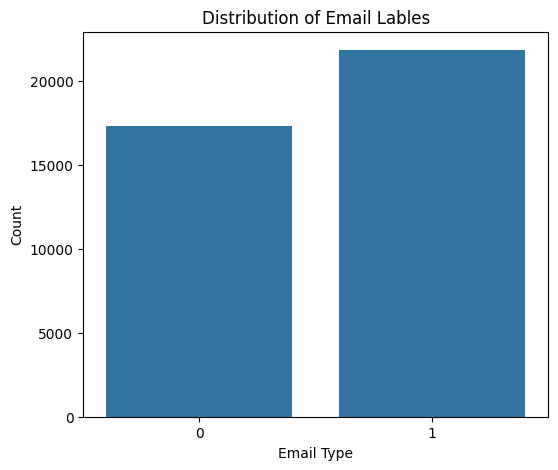

In [7]:
# Label Distribution
df['label'].value_counts()

plt.figure(figsize=(6,5))
sns.countplot(data=df,x='label')
plt.title("Distribution of Email Lables")
plt.xlabel("Email Type")
plt.ylabel("Count")
plt.show()

In [8]:
df['text'] = (
    df['subject'].fillna('') + " " +
    df['body'].fillna('')
)

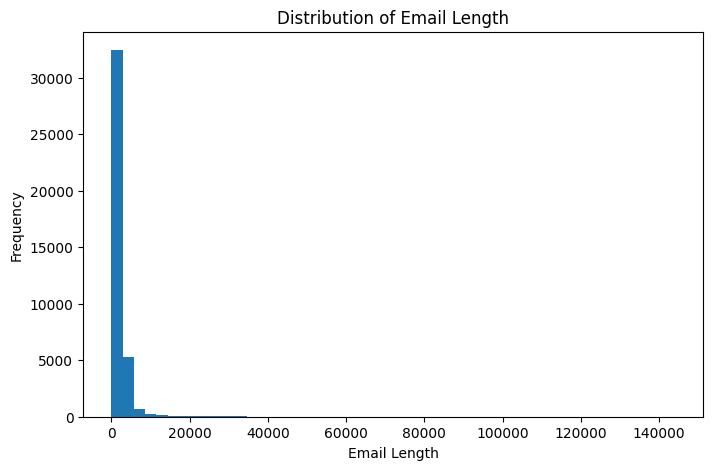

In [9]:
# Email Length
df['Email_Length'] = df['text'].apply(len)
df['Email_Length'].describe()

plt.figure(figsize=(8,5))
plt.hist(df['Email_Length'],
         bins=50)
plt.title("Distribution of Email Length")
plt.xlabel("Email Length")
plt.ylabel("Frequency")
plt.show()

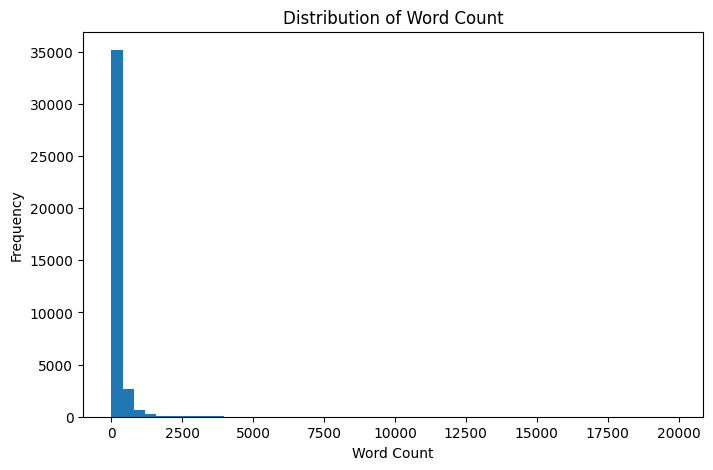

In [10]:
# Word Count
df['Word_Count'] = df['text'].apply(lambda x: len(str(x).split()))
df['Word_Count'].describe()

plt.figure(figsize=(8,5))
plt.hist(df['Word_Count'],
         bins=50)
plt.title("Distribution of Word Count")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()

In [11]:
df['urls'].value_counts().head(10)
df.head()

,sender,receiver,date,subject,body,label,urls,text,Email_Length,Word_Count
0,Young Esposito <Young@iworld.de>,user4@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 16:31:02 -0700",Never agree to be a loser,"Buck up, your troubles caused by small dimension will soon be over!\nBecome a lover no woman wil...",1,1,"Never agree to be a loser Buck up, your troubles caused by small dimension will soon be over!\nB...",299,52
1,Mok <ipline's1983@icable.ph>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 18:31:03 -0500",Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these techniques http://www.brightmade.com\n\n\n,1,1,Befriend Jenna Jameson \nUpgrade your sex and pleasures with these techniques http://www.brightm...,105,12
2,Daily Top 10 <Karmandeep-opengevl@universalnet.psi.br>,user2.9@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 20:28:00 -1200",CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+= >THE DAILY TOP 10 >from CNN.com >T...,1,1,CNN.com Daily Top 10 >+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+= >THE DAILY TO...,3939,306
3,Michael Parker <ivqrnai@pobox.com>,SpamAssassin Dev <xrh@spamassassin.apache.org>,"Tue, 05 Aug 2008 17:31:20 -0600",Re: svn commit: r619753 - in /spamassassin/trunk: lib/Mail/SpamAssassin/PerMsgStatus.pm lib/Mail...,Would anyone object to removing .so from this list? The .so TLD is \nbasically dead and we've ...,0,1,Re: svn commit: r619753 - in /spamassassin/trunk: lib/Mail/SpamAssassin/PerMsgStatus.pm lib/Mail...,24569,2670
4,Gretchen Suggs <externalsep1@loanofficertool.com>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 19:31:21 -0400",SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7iwfna.blu.livefilestore.com/y1pXdX3kwzhBa8xhXv8tdH...,1,1,SpecialPricesPharmMoreinfo \nWelcomeFastShippingCustomerSupport\nhttp://7iwfna.blu.livefilestore...,202,3


In [13]:
# Data Preprocessing
import nltk
import re
import string

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [14]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [15]:
# Missing Values
df['text'] = df['text'].fillna('')

In [16]:
def clean_text(text):
  # Convert to lowercase
  text = text.lower()

  # Remove HTML tags
  text = re.sub(r'<.*?>', ' ', text)

  # Remove URLs
  text = re.sub(r'http\S+|www\S+', ' ', text)

  # Remove email addresses
  text = re.sub(r'\S+@\S+', ' ', text)

  # Remove numbers
  text = re.sub(r'\d+', ' ', text)

  # Remove punctuation
  text = text.translate(str.maketrans('', '', string.punctuation))

  # Remove extra spaces
  text = re.sub(r'\s+', ' ', text).strip()

  return text

In [17]:
df['clean_text'] = df['text'].apply(clean_text)

In [18]:
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

def preprocess(text):

    words = word_tokenize(text)

    words = [word for word in words if word not in stop_words]

    words = [lemmatizer.lemmatize(word) for word in words]

    return " ".join(words)

In [20]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [21]:
df['processed_text'] = df['clean_text'].apply(preprocess)
df[['text','clean_text','processed_text']].head(10)
print("Empty Processed Emails :",
      (df['processed_text']=="").sum())
df = df[df['processed_text']!=""]
df.reset_index(drop=True, inplace=True)

Empty Processed Emails : 0


In [22]:
df.head()

,sender,receiver,date,subject,body,label,urls,text,Email_Length,Word_Count,clean_text,processed_text
0,Young Esposito <Young@iworld.de>,user4@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 16:31:02 -0700",Never agree to be a loser,"Buck up, your troubles caused by small dimension will soon be over!\nBecome a lover no woman wil...",1,1,"Never agree to be a loser Buck up, your troubles caused by small dimension will soon be over!\nB...",299,52,never agree to be a loser buck up your troubles caused by small dimension will soon be over beco...,never agree loser buck trouble caused small dimension soon become lover woman able resist come e...
1,Mok <ipline's1983@icable.ph>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 18:31:03 -0500",Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these techniques http://www.brightmade.com\n\n\n,1,1,Befriend Jenna Jameson \nUpgrade your sex and pleasures with these techniques http://www.brightm...,105,12,befriend jenna jameson upgrade your sex and pleasures with these techniques,befriend jenna jameson upgrade sex pleasure technique
2,Daily Top 10 <Karmandeep-opengevl@universalnet.psi.br>,user2.9@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 20:28:00 -1200",CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+= >THE DAILY TOP 10 >from CNN.com >T...,1,1,CNN.com Daily Top 10 >+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+= >THE DAILY TO...,3939,306,cnncom daily top the daily top from cnncom top videos and stories as of aug pm edt top videos mo...,cnncom daily top daily top cnncom top video story aug pm edt top video montauk monster devil dog...
3,Michael Parker <ivqrnai@pobox.com>,SpamAssassin Dev <xrh@spamassassin.apache.org>,"Tue, 05 Aug 2008 17:31:20 -0600",Re: svn commit: r619753 - in /spamassassin/trunk: lib/Mail/SpamAssassin/PerMsgStatus.pm lib/Mail...,Would anyone object to removing .so from this list? The .so TLD is \nbasically dead and we've ...,0,1,Re: svn commit: r619753 - in /spamassassin/trunk: lib/Mail/SpamAssassin/PerMsgStatus.pm lib/Mail...,24569,2670,re svn commit r in spamassassintrunk libmailspamassassinpermsgstatuspm libmailspamassassinutilre...,svn commit r spamassassintrunk libmailspamassassinpermsgstatuspm libmailspamassassinutilregistra...
4,Gretchen Suggs <externalsep1@loanofficertool.com>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 19:31:21 -0400",SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7iwfna.blu.livefilestore.com/y1pXdX3kwzhBa8xhXv8tdH...,1,1,SpecialPricesPharmMoreinfo \nWelcomeFastShippingCustomerSupport\nhttp://7iwfna.blu.livefilestore...,202,3,specialpricespharmmoreinfo welcomefastshippingcustomersupport,specialpricespharmmoreinfo welcomefastshippingcustomersupport


In [23]:
# Feature Engineering
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

In [24]:
# Email Length
df['Email_Length'] = df['text'].apply(len)

# Word Count
df['Word_Count'] = df['text'].apply(lambda x: len(str(x).split()))

# Subject Length
df['Subject_Length'] = df['subject'].fillna('').apply(len)

# URL Count
df['URL_Count'] = df['urls'].fillna('').apply(lambda x: len(str(x).split()))

In [25]:
df[['Email_Length',
    'Word_Count',
    'Subject_Length',
    'URL_Count']].head()

,Email_Length,Word_Count,Subject_Length,URL_Count
0,299,52,25,1
1,105,12,22,1
2,3939,306,20,1
3,24569,2670,150,1
4,202,3,26,1


In [27]:
# apply tf-idf
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.95
)

X_text = tfidf.fit_transform(df['processed_text'])

# prepare metadata matrix
metadata = df[['Email_Length',
               'Word_Count',
               'Subject_Length',
               'URL_Count']]

In [28]:
X = hstack([X_text, metadata.values])
y = df['label']
print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)
print(df['label'].value_counts())

Feature Matrix Shape: (39154, 5004)
Target Shape: (39154,)
label
1    21842
0    17312
Name: count, dtype: int64


In [29]:
# Train and Test Set
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data :", X_train.shape)
print("Testing Data :", X_test.shape)

Training Data : (31323, 5004)
Testing Data : (7831, 5004)


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

In [31]:
# Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
print("Logistic Regression Model Trained Successfully.")

Logistic Regression Model Trained Successfully.


In [32]:
# Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
print("Naive Bayes Model Trained Successfully.")

Naive Bayes Model Trained Successfully.


In [33]:
# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)
print("Random Forest Model Trained Successfully.")

Random Forest Model Trained Successfully.


In [34]:
# Neural Networks
nn_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=42
)
nn_model.fit(X_train, y_train)
print("Neural Network Model Trained Successfully.")

Neural Network Model Trained Successfully.


In [ ]:
print("All models have been trained successfully.")
print()

print("1. Logistic Regression")
print("2. Naive Bayes")
print("3. Random Forest")
print("4. Neural Network")

In [35]:
# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [36]:
# Logistic Regression
lr_pred = lr_model.predict(X_test)

# Naive Bayes
nb_pred = nb_model.predict(X_test)

# Random Forest
rf_pred = rf_model.predict(X_test)

# Neural Network
nn_pred = nn_model.predict(X_test)

In [37]:
def evaluate_model(model_name, y_true, y_pred):

    print("="*60)
    print(model_name)
    print("="*60)

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    print("\nClassification Report\n")
    print(classification_report(y_true, y_pred))

    return accuracy, precision, recall, f1

In [38]:
lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_pred
)

nb_results = evaluate_model(
    "Naive Bayes",
    y_test,
    nb_pred
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_pred
)

nn_results = evaluate_model(
    "Neural Network",
    y_test,
    nn_pred
)

Logistic Regression
Accuracy  : 0.9944
Precision : 0.9944
Recall    : 0.9944
F1-Score  : 0.9944

Classification Report

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      3462
           1       0.99      1.00      0.99      4369

    accuracy                           0.99      7831
   macro avg       0.99      0.99      0.99      7831
weighted avg       0.99      0.99      0.99      7831

Naive Bayes
Accuracy  : 0.8351
Precision : 0.8536
Recall    : 0.8351
F1-Score  : 0.8299

Classification Report

              precision    recall  f1-score   support

           0       0.94      0.67      0.78      3462
           1       0.79      0.96      0.87      4369

    accuracy                           0.84      7831
   macro avg       0.86      0.82      0.83      7831
weighted avg       0.85      0.84      0.83      7831

Random Forest
Accuracy  : 0.9945
Precision : 0.9945
Recall    : 0.9945
F1-Score  : 0.9945

Classification Report



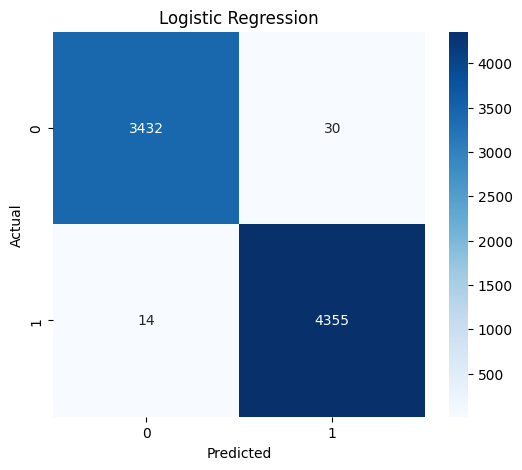

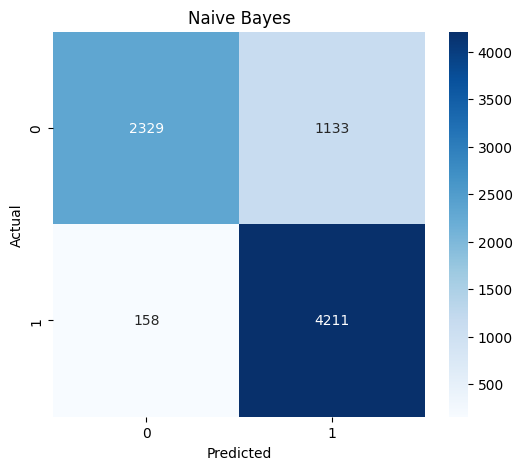

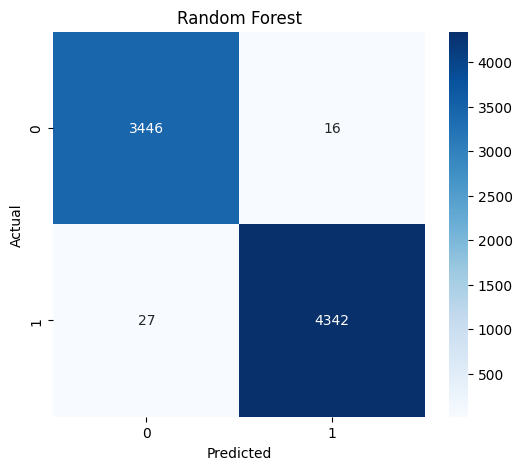

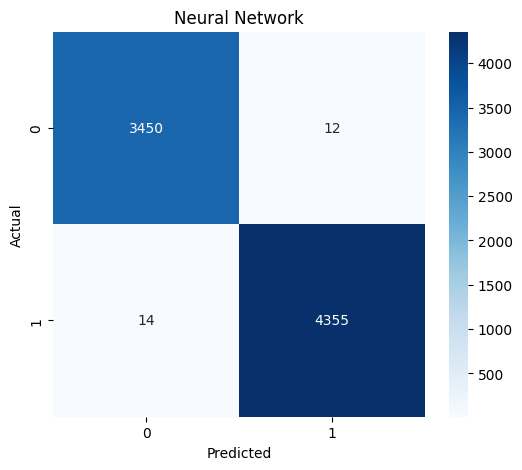

In [40]:
def plot_confusion(model_name, y_true, y_pred):

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6,5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )
    plt.title(model_name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

plot_confusion(
    "Logistic Regression",
    y_test,
    lr_pred
)

plot_confusion(
    "Naive Bayes",
    y_test,
    nb_pred
)

plot_confusion(
    "Random Forest",
    y_test,
    rf_pred
)

plot_confusion(
    "Neural Network",
    y_test,
    nn_pred
)

In [41]:
comparison = pd.DataFrame({

    "Model":[
        "Logistic Regression",
        "Naive Bayes",
        "Random Forest",
        "Neural Network"
    ],

    "Accuracy":[
        lr_results[0],
        nb_results[0],
        rf_results[0],
        nn_results[0]
    ],

    "Precision":[
        lr_results[1],
        nb_results[1],
        rf_results[1],
        nn_results[1]
    ],

    "Recall":[
        lr_results[2],
        nb_results[2],
        rf_results[2],
        nn_results[2]
    ],

    "F1-Score":[
        lr_results[3],
        nb_results[3],
        rf_results[3],
        nn_results[3]
    ]

})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.994381,0.994387,0.994381,0.994380
1,Naive Bayes,0.835142,0.853629,0.835142,0.829907
2,Random Forest,0.994509,0.994515,0.994509,0.994510
3,Neural Network,0.996680,0.996680,0.996680,0.996680


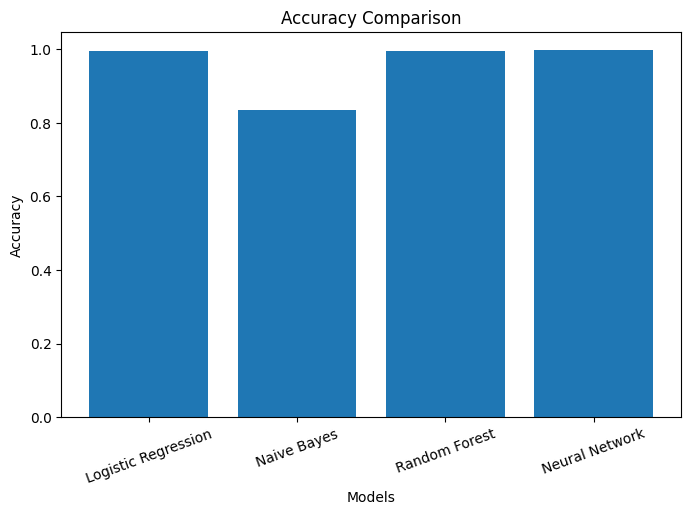

In [42]:
plt.figure(figsize=(8,5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)
plt.title("Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.show()

In [43]:
best_model = comparison.loc[
    comparison["Accuracy"].idxmax()
]

print(best_model)

feature_importance = pd.DataFrame({

    "Importance": rf_model.feature_importances_

})

feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

Model        Neural Network
Accuracy            0.99668
Precision           0.99668
Recall              0.99668
F1-Score            0.99668
Name: 3, dtype: object


,Importance
5000,0.060021
5001,0.048451
4954,0.034315
2455,0.018221
2687,0.017689
2567,0.017438
4942,0.015787
4645,0.013977
2568,0.013822
2438,0.013177


In [45]:
import joblib

joblib.dump(rf_model, "best_phishing_model.pkl")
print("Best model saved successfully.")

joblib.dump(tfidf, "tfidf_vectorizer.pkl")
print("TF-IDF Vectorizer saved successfully.")

Best model saved successfully.
TF-IDF Vectorizer saved successfully.


In [46]:
import re
import string

def clean_new_email(text):

    text = text.lower()

    text = re.sub(r'<.*?>', ' ', text)

    text = re.sub(r'http\S+|www\S+', ' ', text)

    text = re.sub(r'\S+@\S+', ' ', text)

    text = re.sub(r'\d+', ' ', text)

    text = text.translate(str.maketrans('', '', string.punctuation))

    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [48]:
def predict_email(subject, body):

    email = subject + " " + body

    cleaned = clean_new_email(email)

    processed = preprocess(cleaned)

    tfidf_features = tfidf.transform([processed])

    email_length = len(email)

    word_count = len(email.split())

    subject_length = len(subject)

    url_count = len(re.findall(r'http\S+|www\S+', email))

    metadata = np.array([[

        email_length,
        word_count,
        subject_length,
        url_count

    ]])

    final_features = hstack([

        tfidf_features,

        metadata

    ])

    prediction = rf_model.predict(final_features)

    return prediction[0]

In [53]:
subject = "Urgent! Verify Your Bank Account"

body = """
Your account has been suspended.
Click the link below immediately.
http://fake-bank-login.com

"""
prediction = predict_email(subject, body)
print("Prediction :", prediction)

Prediction : 1


In [54]:
subject = "Project Meeting"

body = """
Hello Team,
Tomorrow we have our project meeting at 10 AM.
Please bring your progress report.

Thank you.
"""
prediction = predict_email(subject, body)
print("Prediction :", prediction)

Prediction : 0


In [52]:
comparison
print("Best Model")
print(best_model)

Best Model
Model        Neural Network
Accuracy            0.99668
Precision           0.99668
Recall              0.99668
F1-Score            0.99668
Name: 3, dtype: object
